<a href="https://colab.research.google.com/github/mohsenzh124-dotcom/ML-2025/blob/main/lab1_binary_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная №1 — Анализ бинарных изображений классическими алгоритмами с использованием библиотек компьютерного зрения**


### **Цель работы:** получение навыков работы с библиотеками компьютерного зрения **OpenCV** и **dlib** для базовых задач обработки изображений.


### **Теоретические сведения**


Обработка изображений, компьютерное зрение, распознавание образов и машинное обучения являются тесно связанными областями и, как правило, при решении сложных задач практически все они реализуются в прикладных системах.  

**Обработка изображений** (в узком смысле) решает задачи преобразования изображений, поэтому исходными и результирующими данными этого этапа являются цифровые изображения. В прикладном плане – это построение некоторой системы (или программного комплекса), которая решает определенный класс задач от получения цифрового изображения до интерпретации его содержания и извлечения некоторой информации.  

**Компьютерное зрение** (Computer (Machine) Vision) занимается анализом образов. Для некоторой сцены (аудитория, комната и др.) компьютер должен дать ее описание (есть ли в ней предметы, какая освещенность и т. д.). Таким образом, компьютерное «зрение» переводит изображение в описание.

**Распознавание** – это процесс отнесения изображения к некоторому
определенному классу. В широком смысле допустимо трактовать распознавание как построение полной модели изображения, которую можно воспроизвести посредством машинной графики.

Изображения представляют собой специфический вид информации. Одной из особенностей является избыточность практически любого изображения. Причем изображение одной и той же сцены реального мира несет разную информацию разным пользователям, что не позволяет значительно уменьшить объем данных, содержащихся, например, в космическом снимке, хранящемся в базе данных изображений.

**Цифровым изображением** называются данные, организованные в виде числового массива, воспроизводящего свойства некоторой реальной сцены или синтезированного человеком объекта (чертежа, карты) и тесно связанного со способом получения этих данных.

С формальной точки зрения цифровое изображение представляется  в виде матрицы действительных чисел F с элементами fij (каждому элементу ставится в соответствие некоторое число – код яркости, обычно от 0 до 255), где ij – целочисленные координаты. Причем принято за начало координат принимать левый верхний угол изображения, где i =0, j = 0.  
С использованием введенных обозначений можно компактно записать полное цифровое изображение размерами MxN в форме матрицы F:  
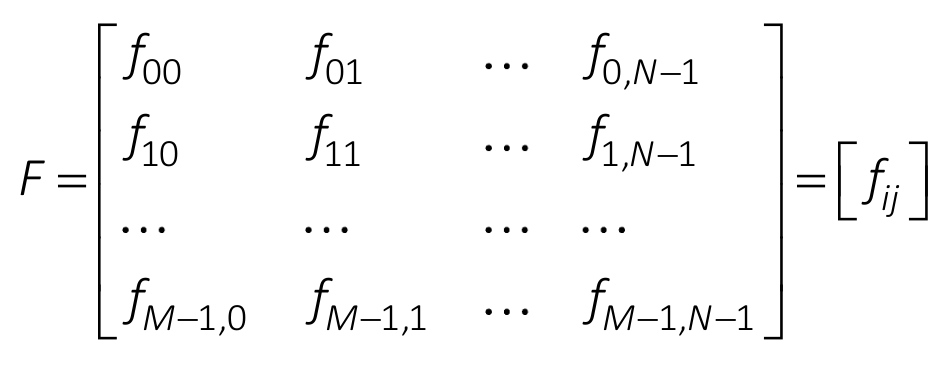

Каждый элемент этой матрицы называется элементом изображения или пикселем (pixel от английского picture element). Каждый пиксель цветного изображения в системах компьютерного зрения описывается тремя уровнями яркости – красным (R), зеленым (G) и синим (B) в диапазоне от 0 до 255.  

В качестве примеров систем, использующих информацию из изображений и видео, требующих применения методов обработки изображений, компьютерного зрения и распознавания образов можно привести системы управления процессами (промышленные роботы, автономные транспортные средства); системы видеонаблюдения с автоматизированным или автоматическим анализом видеоданных; системы организации информации (например, индексация баз данных изображений); системы моделирования объектов или окружающей среды (анализ медицинских изображений, топографическое моделирование); системы человеко-машинного взаимодействия; системы дополненной реальности и др.

Множество методов обработки изображений делится на **методы  обработки в частотной и пространственной областях**. Термин пространственная область относится к плоскости изображения как таковой, и данная категория объединяет подходы, основанные на прямом манипулировании пикселями изображения. Способы обработки изображений в частотной  области (после применения дискретного преобразования Фурье) достаточно развиты, но требуют значительно больших вычислительных затрат и для решения практических задач применяются реже.

В общем виде процессы пространственной обработки изображений описываются выражением
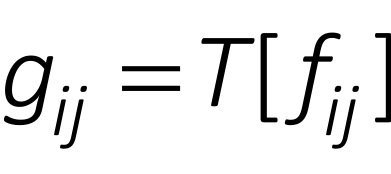


где 	fij – элементы входного изображения F;  
gij – элементы обработанного изображения G;  
T – оператор преобразования входного изображения в окрестности точки с координатами (ij).  

**Под окрестностью вокруг точки** понимают квадратную или прямоугольную область изображения, которая центрирована в точке с координатами (ij). Простейшая форма оператора достигается в случае, когда окрестность имеет размеры 1×1. При этом значение g зависит только от значения f в точке (ij) и оператор T становится функцией градационного преобразования (функцией преобразования интенсивностей или функцией отображения).

**Бинаризация** – это преобразование полутонового изображения к одноцветному (монохромному или бинарному).

Пусть fij – полутоновое изображение, t – порог и b0 , b1 – два бинарных значения (для бинарного черно-белого b0=0, b1=255). Результат порогового разделения – бинарное изображение gij , полученное следующим образом:
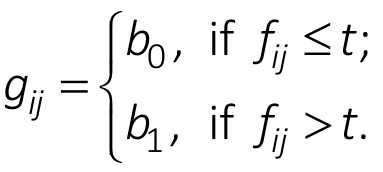

Основной задачей является выбор значения t с помощью некоторого критерия. Это значение может выбираться как одинаковым для всего изображения, так и различным для различных его частей. Если значения объектов и фона режима достаточно однородны по всему изображению, то может использоваться одно пороговое значение для всего изображения. Использование единственного значения порога для всех пикселей изображения называется глобальным пороговым разделением. Методика локального порогового разделения предполагает определение порога для области изображения или пикселей. Такие алгоритмы называются адаптивными алгоритмами бинаризации, к ним можно отнести метод Оцу, Брэдли и др.

### **Библиотека компьютерного зрения OpenCV**

OpenCV (Open Source Computer Vision, https://opencv.org/) – библиотека компьютерного зрения с открытым исходным кодом и широким спектром возможностей. Функциональность OpenCV доступна на языках C, C++, Python, Java, Ruby. Поддерживаются основные операционные системы:  MS Windows, Linux, Mac, Android, iOS.  

Библиотека включает большое количество оптимизированных классических и современных алгоритмов обработки изображений, распознавания образов, компьютерного зрения и машинного обучения, которые могут быть использованы для обнаружения и распознавания лиц, идентификации разных классов объектов, анализа действий человека в видео, отслеживания движений камеры, сопровождения движущихся объектов на видео и других.  

OpenCV имеет модульную структуру, а это значит, что пакет включает  в себя несколько общих или статических библиотек. Библиотека непрерывно обновляется, в версии OpenCV 4.5.5 доступны:
1. модуль *core* определяет основные структуры данных, используемые всеми остальными модулями, такие как:
   * операции с массивами;
   * сохранение XML/YAML/JSON;
   *	кластеризация;
   *	утилиты, системные функции и макросы;
   *	совместимость с OpenGL;
   *	алгоритмы оптимизации;
   *	параллельная обработка;
   *	аппаратное ускорение;
2.	модуль *imgproc* предназначен для обработки изображений и включает:
   * фильтрацию изображений;
   * геометрические преобразования;
   *	функции рисования;
   *	функции преобразования цветного пространства;
   *	анализ гистограмм;
   *	обнаружение признаков;
   *	сегментацию;
   *	обнаружение объектов;
3.	модуль *imgcodecs* используется для чтения и записи изображений;
4.	модуль *videoio* предназначен для чтения и записи видео или последовательности изображений;
5.	модуль *highgui* – графический интерфейс высокого уровня. Позволяет создавать и управлять окнами, которые могут отображать изображения и «запоминать» их содержимое;  
6.	модуль *video*, предназначенный для анализа видео, включающий алгоритмы оценки движения, вычитания фона и отслеживания объектов;
7.	модуль *calib3d* – калибровка камеры и 3D-реконструкция. Включает основные алгоритмы геометрии с несколькими видами, калибровку одиночной и стереокамеры, оценку позы объекта, алгоритмы стереосоответствия и элементы 3D-реконструкции;
8.	модуль *features2d* включает детекторы признаков, дескрипторы  и средства сопоставления дескрипторов:
  *	обнаружение и описание признаков;
  *	сопоставление дескрипторов;
  *	рисование ключевых точек и совпадений;
  *	классификация объектов;
9.	модуль *objdetect*, предназначен для обнаружения объектов и экземпляров предопределенных классов (например: лица, глаза, люди, автомобили и т. д.);
10.	модуль *dnn*, предназначен для работы с глубокими нейронными сетями:
   *	инструментарий для загрузки моделей сетей из разных фреймворков;  
   *	реализации готовых слоев нейронных сетей;
   *	утилиты, для создания новых слоев;
11.	модуль *ml* – модуль для машинного обучения. Представляет собой набор классов и функций для статической классификации, регрессии и кластеризации данных;  
12.	модуль *flann* – модуль, содержащий коллекцию алгоритмов, оптимизированных для быстрого поиска ближайших соседей в больших наборах данных;
13.	модуль *photo* – модуль для обработки фотографий:
   *	шумоподавление;
   *	HDR-визуализация (High Dynamic Range Rendering);
   *	обесцвечивание изображений с сохранением контраста;
   *	бесшовное клонирование, которое позволяет скопировать объект с одного изображения на другое таким образом, чтобы комбинация выглядела бесшовной и естественной;
14.	модуль *stitching* используется для сшивания изображений:
   *	поиск признаков и сопоставление изображений;
   *	оценка вращения;
   *	автокалибровка (пытается оценить фокусные расстояния по заданной гомографии исходя из предположения, что камера вращается только вокруг своего центра, и может использоваться для построения панорамных мозаик);
   *	деформация изображений;
   *	оценка швов склеенных изображений;
   *	компенсация экспозиции;
15.	модуль *gapi* – модуль, предназначенный для того, чтобы сделать обычную обработку изображений быстрой и переносимой путем внедрения новой графовой модели, суть которой заключается в построении графа на основе используемых операций к объектам данных. Графы представляются неявной структурой, для описания которой используются не «узлы» и «ребра», а операции и объекты данных. Объекты данных при этом  содержат не фактические значения, а описывают зависимости. Модуль  выступает в качестве фреймворка.
----

**Opencv-contrib** – отдельный репозиторий, содержащий новые расширяющие функциональность модули, которые еще не включены в основную часть. Это связано с тем, что новые модули часто не имеют стабильного интерфейса и плохо протестированы, поэтому их и не включают в официальный дистрибутив OpenCV. Opencv-contrib 4.5.5 содержит ряд модулей, среди них можно выделить основные:
* alphamat (альфа-матирование) предназначен для отделения объекта на переднем плане от фона обеспечивая нерезкие границы. Его можно использовать для дальнейших операций;  
* aruco предоставляет возможности обнаружения двоичных квадратных реперных маркеров и инструменты для их использования при оценке позы человека и калибровке камеры;  
* barcode служит для обнаружения и декодирования штрих-кодов;  
* bgsegm применяется для вычитания фона при обработке видео;  
* bioinspired позволяет обрабатывать как изображения, вызывающие оптические иллюзии, так и обычные;
* ccalib предназначен для калибровки одной камеры, стереопары  и многокамерных систем. Позволяет удалять большие искажения на изображениях, а также реконструировать 3D-сцены на основе двух стереоизображений;  
* cvv может быть использован для отладки приложений с использованием визуального пользовательского интерфейса;  
* dnn_objdetect служит для обнаружения объектов с использованием глубоких сверточных нейронных сетей;  
* dnn_superres позволяет обрабатывать изображения сверхвысокого разрешения, также включает функции масштабирования фото и видео;  
* face предназначен для обнаружения и распознавания лиц на изображениях;  
* fuzzy. Модуль реализует алгоритмы обработки изображений, основанные на нечеткой математике;  
* mcc применяется для цветокоррекции с использованием Color correction Model;  
* tracking используется для сопровождения различных объектов  на видео;  
* ximgproc предназначен для фильтрации несоответствий на стереоизображениях, может быть использован для быстрого обнаружения границ
с использованием алгоритма Structured Forest;  
* xphoto применяется для восстановления поврежденных или отсутствующих частей изображения.

## **Библиотека компьютерного зрения dlib**

Библиотека dlib включает реализацию множества традиционных математических функций, операций линейной алгебры, а также алгоритмов сжатия данных, классической обработки изображений и алгоритмов на основе машинного обучения, реализованных в основном на языке C++, однако ряд инструментов dlib возможно использовать и на Python.

Лицензирование dlib с открытым исходным кодом позволяет использовать ее бесплатно. Следует выделить следующие основные инструменты в dlib версии 19.23:  
1. для обработки изображений – функции для работы с различными типами пикселей; чтение и запись различных форматов изображений, таких как BMP, PNG, JPEG, GIF и формат dlib файла DNG; автоматическое преобразование цветового пространства; алгоритмы поиска объектов на изображениях; традиционные операции с изображениями, такие как поиск краев и морфологические операции и др.; алгоритмы извлечения признаков SURF (Speeded Up Robust Features, Ускоренные надежные признаки), HOG (Histogram of Oriented Gradients, Гистограмма направленных градиентов) и FHOG (Felzenszwalb Histogram of Oriented Gradients, Гистограмма направленных градиентов Фельзеншвальба);
2. для машинного обучения – алгоритмы бинарной и многоклассовой классификации, регрессионного и структурного анализа, кластеризации, глубокого обучения, обучения без учителя, обучения с подкреплением;  
3. для метапрограммирования – предоставляются функциональные возможности для отладки, выполнения различных операций с шаблонами. Включает большое число макрофункций;  
4. для вычислений:
   * быстрые алгоритмы обработки матричных объектов;
   * многочисленные функции линейной алгебры и математические операции;
5.	для оптимизации dlib включает нелинейные оптимизаторы общего назначения;  
6.	для работы с сетью в dlib имеется набор объектов для создания многопоточных программ, для обеспечения соединения между сетевыми приложениями, для создания сервера и т. д.
7.	для работы с текстом имеются инструменты для анализа и различных манипуляций: преобразования кодировок, работы со строками, анализа параметров аргументов командной строки и др.

## **Задания к лабораторной работе**


1.  Общие правила для всех вариантов

**Дано**: сгенерируйте 3 изображения различной сложности: разное освещение, шум, объекты с отверстиями. Выполнить преобразования согласно своему варианту. Исследовать влияние параметров функций, необходимых для выполнения преобразования.

*Описание функций OpenCV4.5.5, необходимых для выполнения данной работы представлено в ПРИЛОЖЕНИИ 1.*

Подписать на изображении выполненное преобразование и свою фамилию.

**Бинаризация**: как минимум 2 метода (один глобальный: Fixed/Otsu/Triangle и т.д.; один адаптивный: Mean/Gaussian/Niblack/Sauvola/Bradley и т.д.) — сравнить.

**Морфология**: минимум 1 операция из {erosion, dilation, opening, closing, top-hat, black-hat, morph.gradient} с обоснованием выбора структурного элемента.

**Маркировка СК**: 8-связность, таблица свойств областей.

**Подсчёт объектов:**

способ A — через внешние и внутренние углы (по аппроксимированным контурам);

способ B — через эйлерову характеристику (компоненты/дыры).
Сравнить устойчивость при шуме/морф.правках.

**Выводы:** что лучше для ваших изображений и почему; метрики (IoU, Precision/Recall по маске, ошибка счёта).

При необходимости установить OpenCV и dlib.

**Реализовать следующие операции обработки изображений:**

**Вариант 1**. Кадрирование → Оtsu vs Fixed → opening/closing → СК/свойства → подсчёт (углы & Эйлер).
Особый акцент: покажите гистограмму кропа и обоснуйте, почему Otsu выигрывает/не выигрывает у ручного порога.

**Вариант 2**.Поворот (±15–45°) → бинаризация Triangle vs Otsu → морф.градиент для подчёркивания границ → СК/свойства → подсчёт.
Сравните инвертированный/неинвертированный порог (объекты светлее/темнее фона).

**Вариант 3**. Масштабирование (↑ или ↓) → подавление шума (Gaussian/Bilateral) → адаптивная Mean vs Gaussian → closing для «заплатки» дыр → СК/свойства → подсчёт.
Поиграйте block_size и C; покажите влияние масштаба на качество маски.

**Вариант 4**. Кадрирование → unsharp/повышение резкости только для подготовки → Otsu → opening для шумов → СК/свойства → подсчёт.
Сравните Otsu «до» и «после» повышения резкости (улучшилась ли межклассовая разделимость?).

**Вариант 5.** Поворот → линейное растяжение контраста (alpha/beta) → Otsu vs Triangle → closing → СК/свойства → подсчёт.
Сделайте график «IoU от alpha» (несколько значений).

**Вариант 6.** Масштабирование → CLAHE → адаптивная Sauvola vs Bradley → opening/closing (сравнить) → СК/свойства → подсчёт.
Покажите, кто лучше переживает неравномерную подсветку.

**Вариант 7.** Кадрирование → любая удачная бинаризация → контуры + аппроксимация (Douglas–Peucker) → подсчёт через внешние/внутренние углы → СК/свойства → сравнение с Эйлером.
Здесь упор на «угловой» метод: покажите сумму внутренних углов и связь с числом объектов/дыр.

**Вариант 8.** Поворот → top-hat (фоновые неравномерности) → Otsu/Triangle → morph.gradient для контроля границ → СК/свойства → подсчёт.
Объясните, как top-hat повлиял на фоновую засветку.

**Вариант 9.** Масштабирование → разделение слипшихся объектов (opening с диском/крестом, затем watershed по желанию) → бинаризация (на ваш выбор) → СК/свойства → подсчёт.
Покажите, как меняется число компонентов при изменении размера структурного элемента.

**Вариант 10.** Кадрирование → линейный контраст → Bradley (T·локальное среднее) → closing → СК/свойства → подсчёт.
Сделайте краткую «теплокарту» ошибок в зависимости от T∈[0.7…0.95].

**Вариант 11.** Поворот → CLAHE → Niblack vs Otsu → opening/closing → СК/свойства → подсчёт.
Особый акцент: покажите гистограмму обоснуйте, почему Otsu выигрывает/не выигрывает у аддаптивного порога.

**Вариант 12.** Масштабирование → шумоподавление (Median для «соли/перца») → Otsu vs Adaptive Mean → closing → СК/свойства → подсчёт.
Сравните медианный vs гауссовский фильтры перед порогованием.

**Вариант 13.** Кадрирование → black-hat (подчёркивание «ям») → адаптивная (Gauss/Sauvola) → hit-or-miss (поиск концевых/углов на скелете, опционально) → СК/свойства → подсчёт.
Покажите найденные концевые точки/углы на тонком скелете объектов.

**Вариант 14.** Поворот → бинаризация → контуры/периметр/выпуклая оболочка → свойства (компактность, прямоугольность, конвексность) → простая классификация форм → подсчёт.
Отчёт о том, какие признаки лучше разделяют ваши формы.

----

2. Загрузить **полноцветные фотографии лица одного и того же человека** с использованием OpenCV (рекомендуется ≥5 снимков; разные условия: освещение/ракурс/шум/очки). Для **каждого** изображения:

   * выполнить детекцию лица и **выделение 68 особых точек** с помощью dlib (`shape_predictor_68_face_landmarks.dat`);
   https://github.com/davisking/dlib-models.git
   * отобразить точки поверх исходного кадра (сохранить визуализацию);
   * при неудаче фиксации лица — зафиксировать сбой (файл/условие) и повторить с изменёнными параметрами/кадром.

Результат выполненя:

* кратко описать условия съёмки каждого кадра;
* оценить **корректность** локализации точек: полнота (все ли 68 найдены), точность расположения на анатомических ориентирах (контур челюсти, уголки глаз/рта), устойчивость к освещению/ракурсу/шуму/очкам;
* указать проблемные случаи и возможные причины (тени, сильный поворот, размытие, низкое разрешение), предложить способы улучшения (кадрирование лица, повышение контраста/CLAHE, другая экспозиция);
* приложить 2–3 показательных примера «хорошо/плохо» с изображениями.

----

##Содержание отчета

1.	Титульный лист.  
2.	Цель лабораторной работы.
3.	Ход работы с пояснениями алгоритмов из первого задания, примерами обработки по заданиям и их анализом.
4.	Результаты выполнения второго пункта задания.
5.	Листинг кода.
6.	Выводы о проделанной работе.



## 0. Импорты Библиотек
OpenCV, NumPy, Matplotlib — для обработки и визуализации; dlib — для задания с ключевыми точками лица.

In [2]:
# @title
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from typing import Tuple, Dict, List
import itertools
import math
import os
import io
from skimage.morphology import skeletonize

from skimage.measure import label, regionprops
from skimage.feature import corner_harris, corner_peaks
from scipy.ndimage import binary_fill_holes


plt.rcParams['figure.figsize'] = (6, 6)

## 0.1) Вспомогательные функции отображения и ввода/вывода

In [3]:
# @title
def put_name(img, text='Фамилия Имя', pos=(20,40), color=(255,80,50)):
    out = img.copy()
    cv.putText(out, text, pos, cv.FONT_HERSHEY_SIMPLEX, 1, color, 2)
    return out

def imshow(img, title=None, cmap=None):
    plt.figure()
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap or 'gray', vmin=0, vmax=255 if img.dtype!=bool else 1)
    else:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img_rgb)
    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

def show_grid(images: List[Tuple[str, np.ndarray]], cols=3):
    rows = int(np.ceil(len(images)/cols))
    plt.figure(figsize=(cols*4, rows*4))
    for i,(title,img) in enumerate(images,1):
        plt.subplot(rows, cols, i)
        if img.ndim==2:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255 if img.dtype!=bool else 1)
        else:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def to_uint8(img):
    if img.dtype==np.bool_:
        return (img.astype(np.uint8))*255
    if img.dtype!=np.uint8:
        img = np.clip(img,0,1) if img.max()<=1.0 else np.clip(img,0,255)
        img = (img*255).astype(np.uint8) if img.max()<=1.0 else img.astype(np.uint8)
    return img

def ensure_gray(img):
    if img.ndim==3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img

def read_image(path):
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if img is None:
        img = cv2.imread(path, cv2.IMREAD_UNCHANGED)  # fallback
    return img

def save_image(path, img):
    img = to_uint8(img)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    cv2.imwrite(path, img)

## 0.2) Генерация синтетического датасета (с известной истиной)
Cгенерируйте 3 изображения различной сложности: разное освещение, шум, объекты с отверстиями.

Истинное число объектов: 18


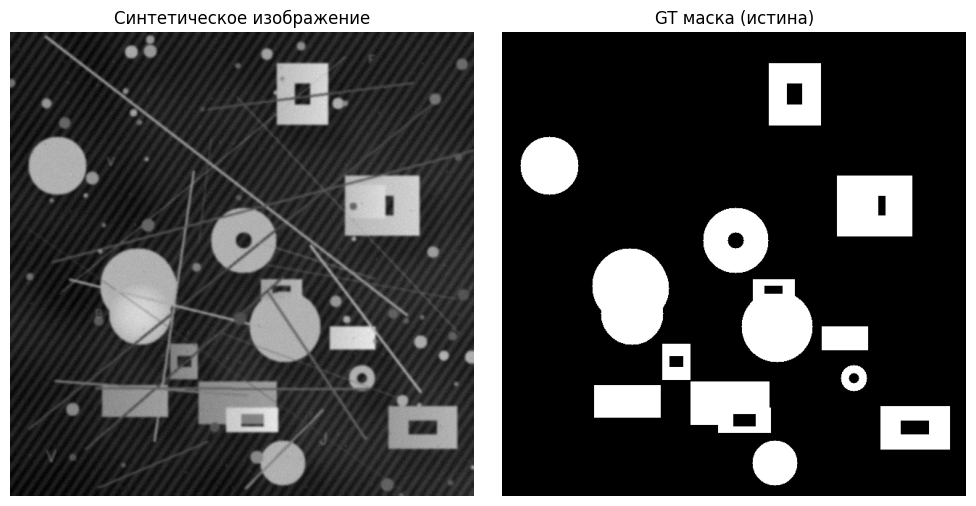

In [4]:
# @title
import numpy as np, cv2 as cv, matplotlib.pyplot as plt

def _lf(h,w,s=20,k=101):
    r=np.random.default_rng();n=r.normal(0,1,(h,w)).astype(np.float32);k=max(3,int(k)|1)
    f=cv.GaussianBlur(n,(k,k),0);f=(f-f.min())/(f.max()-f.min()+1e-9);return s*(f-0.5)
def _vig(h,w,strength=0.35):
    y,x=np.mgrid[0:h,0:w];cx,cy=w/2,h/2;r=np.sqrt((x-cx)**2+(y-cy)**2)/(np.sqrt(cx**2+cy**2)+1e-9)
    return np.clip(1.0-strength*(r**2),0,1).astype(np.float32)
def _tr(img,dx,dy):
    M=np.array([[1,0,float(dx)],[0,1,float(dy)]],np.float32)
    return cv.warpAffine(img,M,(img.shape[1],img.shape[0]),flags=cv.INTER_NEAREST,borderValue=0)
def _sintex(h,w):
    r=np.random.default_rng();ax=int(r.integers(12,28));ay=int(r.integers(18,40));amp=float(r.uniform(6,16));phi=float(r.uniform(0,6.28))
    y,x=np.mgrid[0:h,0:w].astype(np.float32);return amp*(np.sin(2*np.pi*(x/ax+y/ay)+phi))

def generate_synthetic_random(size=(640,640),n_circles=(8,14),n_rects=(6,12),with_holes=True,clutter=0.6):
    r=np.random.default_rng();H,W=size
    img=np.zeros((H,W),np.float32);gt=np.zeros((H,W),np.uint8);obj=0
    gx=np.linspace(r.uniform(0.65,0.85),r.uniform(1.15,1.3),W,np.float32);gy=np.linspace(r.uniform(0.85,0.95),r.uniform(1.05,1.15),H,np.float32)[:,None]
    img+=r.uniform(20,40);img*=gx;img*=gy
    img+=_lf(H,W,s=r.uniform(20,45),k=max(H,W)//int(r.integers(5,9))*2+1)
    img*=_vig(H,W,r.uniform(0.2,0.35));img+=_sintex(H,W);img=np.clip(img,0,255)

    mask=np.zeros((H,W),np.uint8)
    for _ in range(int(r.integers(n_circles[0],n_circles[1]+1))):
        rad=int(r.integers(18,55));cx=int(r.integers(rad+12,W-rad-12));cy=int(r.integers(rad+12,H-rad-12))
        val=float(r.integers(160,240));cv.circle(mask,(cx,cy),rad,255,-1);cv.circle(gt,(cx,cy),rad,255,-1)
        if with_holes and r.random()<0.45:
            rr=max(2,int(rad*r.uniform(0.25,0.5)));cv.circle(mask,(cx,cy),rr,0,-1);cv.circle(gt,(cx,cy),rr,0,-1)
        yy,xx=np.ogrid[:H,:W];d=np.sqrt((xx-cx)**2+(yy-cy)**2);core=np.clip(1-(d/(rad+1e-9))**2,0,1)
        img=np.where(mask==255,(val*(0.86+0.18*core)).astype(np.float32),img);obj+=1

    for _ in range(int(r.integers(n_rects[0],n_rects[1]+1))):
        w=int(r.integers(28,110));h=int(r.integers(24,90));x=int(r.integers(12,W-w-12));y=int(r.integers(12,H-h-12))
        val=float(r.integers(140,220));cv.rectangle(mask,(x,y),(x+w,y+h),255,-1);cv.rectangle(gt,(x,y),(x+w,y+h),255,-1)
        if with_holes and r.random()<0.4:
            ww=max(3,int(w*r.uniform(0.25,0.5)));hh=max(3,int(h*r.uniform(0.25,0.5)))
            cv.rectangle(mask,(x+w//2-ww//2,y+h//2-hh//2),(x+w//2+ww//2,y+h//2+hh//2),0,-1)
            cv.rectangle(gt,(x+w//2-ww//2,y+h//2-hh//2),(x+w//2+ww//2,y+h//2+hh//2),0,-1)
        strip=np.linspace(0.92,1.06,w,np.float32)[None,:];patch=(val*strip);patch=np.repeat(patch,h,0)
        roi=img[y:y+h,x:x+w].copy();m=mask[y:y+h,x:x+w]==255;roi[m]=patch[m];img[y:y+h,x:x+w]=roi;obj+=1

    dx=int(r.integers(12,45));dy=int(r.integers(8,35));sh=(_tr(mask,dx,dy)>0).astype(np.uint8)*255
    ker=cv.getStructuringElement(cv.MORPH_ELLIPSE,(int(r.integers(7,13)),)*2);sh=cv.dilate(sh,ker);sh=cv.GaussianBlur(sh,(int(r.integers(25,41))|1,)*2,0).astype(np.float32)/255.0
    op=r.uniform(0.45,0.7);img=img*(0.75+0.25*(1-op*sh));img=np.where(mask==255,img/np.maximum(0.0001,(0.75+0.25*(1-op*sh))),img)

    p_pts=int((0.0005+0.004*clutter)*H*W)
    for _ in range(p_pts):
        y=int(r.integers(0,H));x=int(r.integers(0,W));img[y,x]=r.choice([0,255],p=[0.6,0.4])
    for _ in range(int(20+120*clutter)):
        x1=int(r.integers(0,W));y1=int(r.integers(0,H));x2=int(r.integers(0,W));y2=int(r.integers(0,H))
        col=int(r.integers(70,200));cv.line(img,(x1,y1),(x2,y2),col,int(r.integers(1,3)))
    for _ in range(int(60+200*clutter)):
        x=int(r.integers(0,W));y=int(r.integers(0,H));rr=int(r.integers(3,10));col=int(r.integers(80,180))
        cv.circle(img,(x,y),rr,col,-1)
    for _ in range(int(5+40*clutter)):
        x=int(r.integers(0,W-60));y=int(r.integers(20,H-10))
        cv.putText(img,chr(int(r.integers(65,91))),(x,y),cv.FONT_HERSHEY_SIMPLEX,r.uniform(0.4,0.8),int(r.integers(120,200)),1,cv.LINE_AA)

    if r.random()<0.7:
        k=int(r.choice([3,5,7]));img=cv.GaussianBlur(img,(k,k),0)
    img+=r.normal(0,r.uniform(4,12),img.shape).astype(np.float32)
    img=np.clip(img,0,255).astype(np.uint8)
    return img,gt,obj

if __name__=='__main__':
    img, gt, n = generate_synthetic_random(clutter=0)
    print(f'Истинное число объектов: {n}')
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Синтетическое изображение'); ax[0].axis('off')
    ax[1].imshow(gt,  cmap='gray', vmin=0, vmax=255); ax[1].set_title('GT маска (истина)');        ax[1].axis('off')
    plt.tight_layout(); plt.show()



Image de Faible Complexité - Vrai nombre d'objets: 10


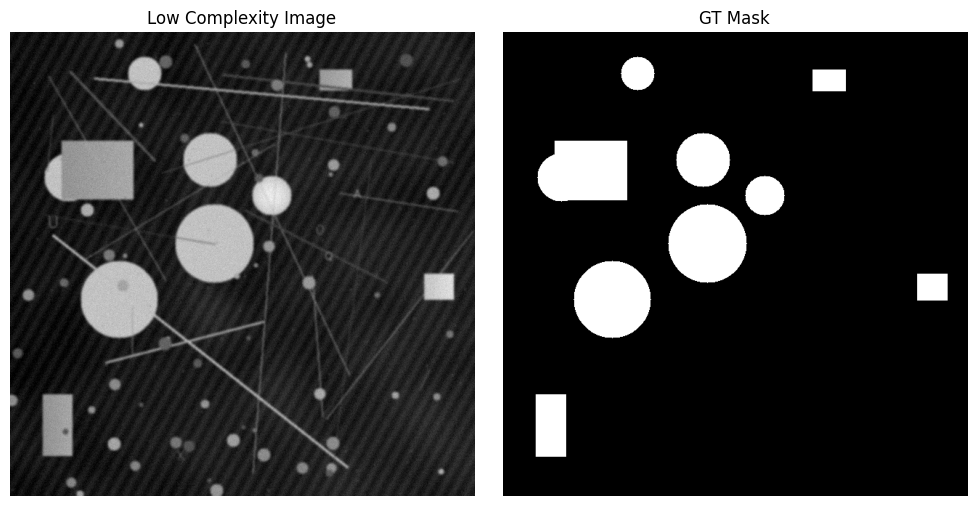

In [5]:
img, gt, n = generate_synthetic_random(
    n_circles=(4, 6),
    n_rects=(2, 4),
    with_holes=False, # Pas de trous
    clutter=0.0 # Pas de bruit/lignes/texte aléatoire
)

print(f'Image de Faible Complexité - Vrai nombre d\'objets: {n}')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Low Complexity Image'); ax[0].axis('off')
ax[1].imshow(gt, cmap='gray', vmin=0, vmax=255); ax[1].set_title('GT Mask'); ax[1].axis('off')
plt.tight_layout(); plt.show()


Image of Medium Complexity - True number of objects: 13


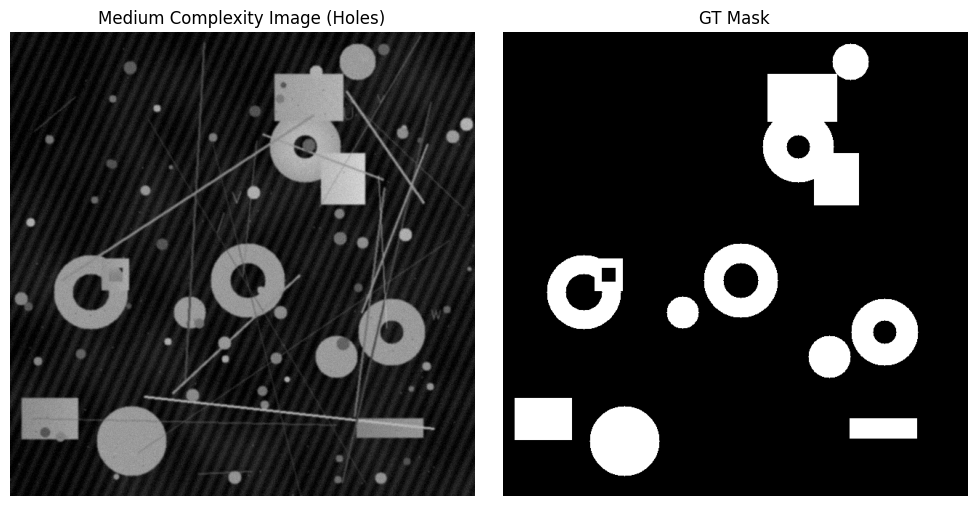

In [6]:
img, gt, n = generate_synthetic_random(
    n_circles=(6, 8),
    n_rects=(3, 5),
    with_holes=True, # Activated holes
    clutter=0.0 # No noise / lines / random text
)

print(f'Image of Medium Complexity - True number of objects: {n}')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Medium Complexity Image (Holes)'); ax[0].axis('off')
ax[1].imshow(gt, cmap='gray', vmin=0, vmax=255); ax[1].set_title('GT Mask'); ax[1].axis('off')
plt.tight_layout(); plt.show()



High Complexity Image - Real number of objects: 27


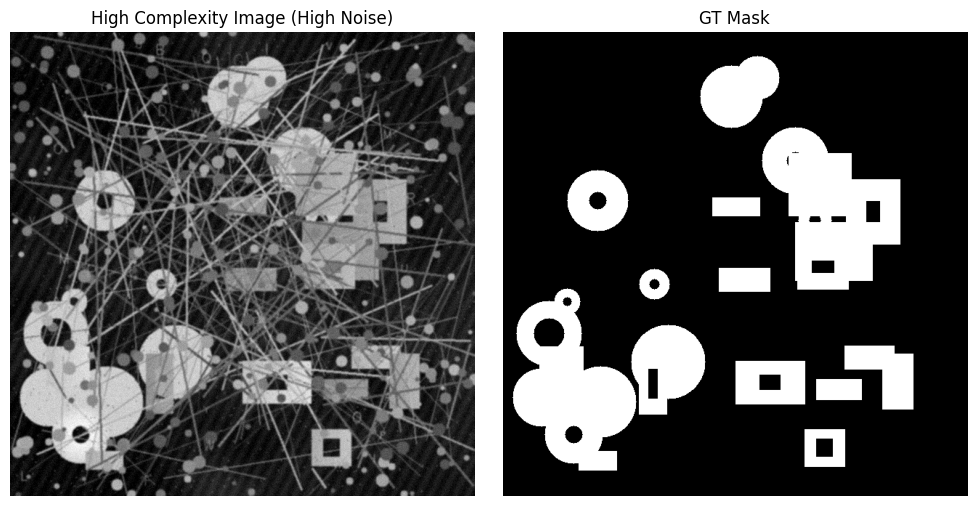

In [7]:
img, gt, n = generate_synthetic_random(
    n_circles=(10, 16), # Many objects
    n_rects=(8, 14), # Many objects
    with_holes=True, # Activated holes
    clutter=1.2 # HIGH random noise/lines/text
)

print(f'High Complexity Image - Real number of objects: {n}')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('High Complexity Image (High Noise)'); ax[0].axis('off')
ax[1].imshow(gt, cmap='gray', vmin=0, vmax=255); ax[1].set_title('GT Mask'); ax[1].axis('off')
plt.tight_layout(); plt.show()

In [8]:
Вариант 1**. Кадрирование → Оtsu vs Fixed → opening/closing → СК/свойства → подсчёт (углы & Эйлер).
Особый акцент: покажите гистограмму кропа и обоснуйте, почему Otsu выигрывает/не выигрывает у ручного порога.

SyntaxError: invalid character '→' (U+2192) (ipython-input-2439058667.py, line 1)

Low Complexity image Generation...
True number of objects: 10


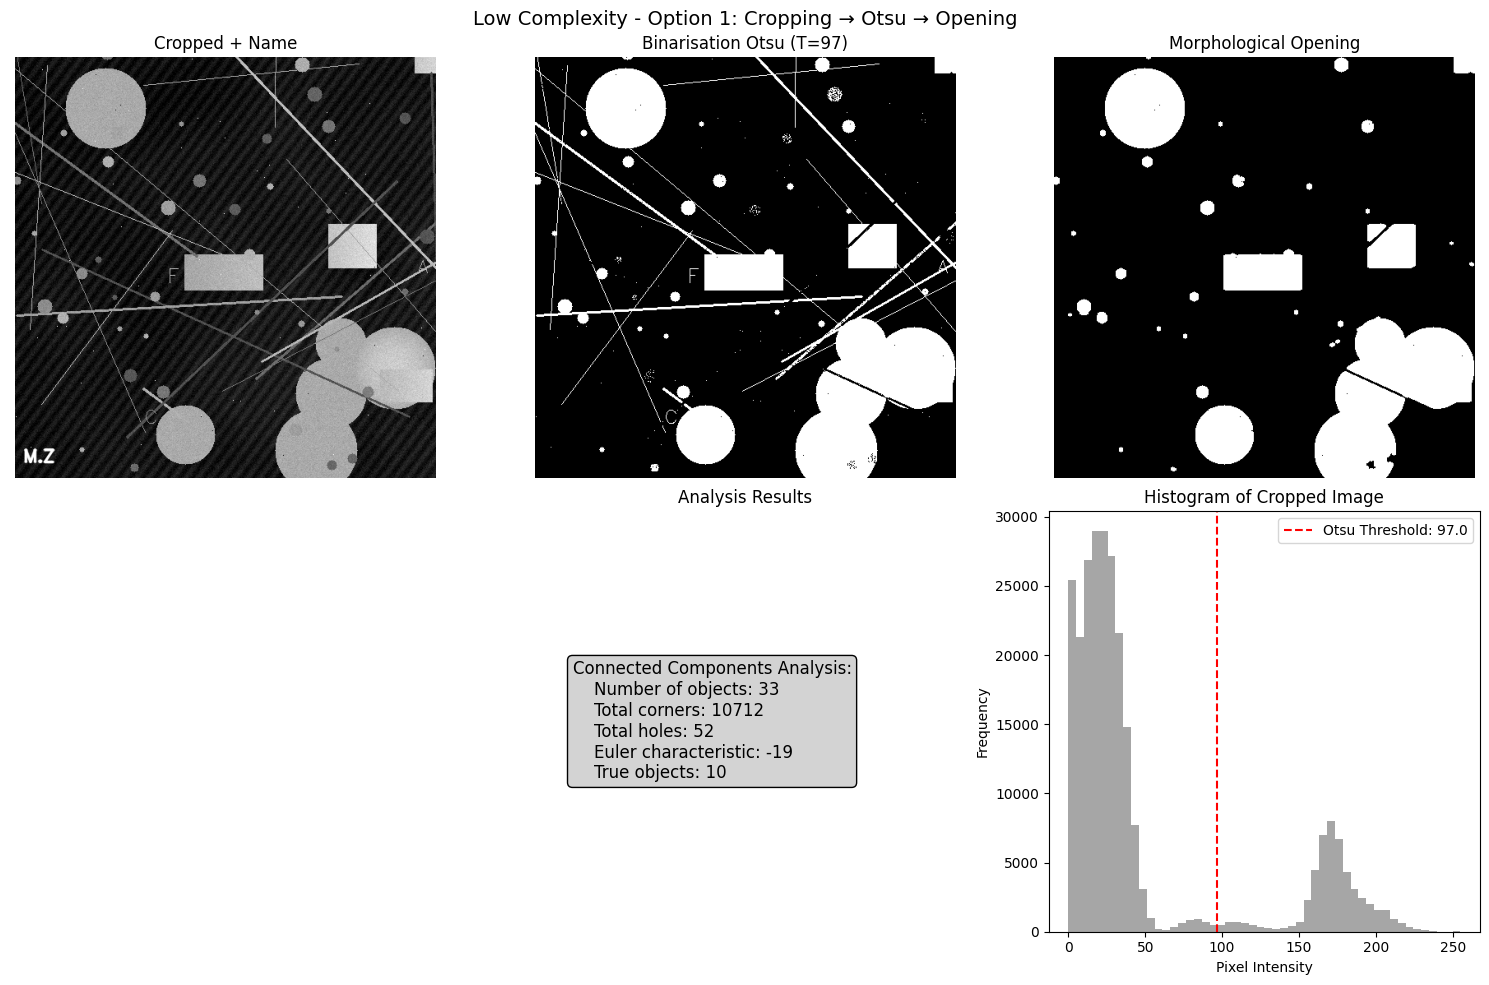


DETAILED ANALYSIS RESULTS:
True number of objects: 10
Detected objects: 33
Total corners found: 10712
Total holes detected: 52
Euler characteristic: -19
Counting error: 23


In [9]:

def analyze_connected_components(binary_img):
    """

    Parameters:
    -----------
    binary_img : np.ndarray
        صورة ثنائية (0 و255 أو False وTrue)

    Returns:
    --------
    dict
        It contains the results of the analysis: the number of objects, angles, holes, Eller.
    """
    # (Boolean)
    bin_img = binary_img > 0

    # Numbering of connected components
    labeled_img = label(bin_img)
    regions = regionprops(labeled_img)

    num_objects = len(regions)
    total_corners = 0
    total_holes = 0

    for region in regions:
        minr, minc, maxr, maxc = region.bbox
        region_img = bin_img[minr:maxr, minc:maxc]

        # Calculation of angles in the body of the area
        corners = corner_peaks(corner_harris(region_img), min_distance=1)
        total_corners += len(corners)

        # Filling holes in the body
        filled = binary_fill_holes(region_img)
        holes = np.sum(filled) - np.sum(region_img)
        total_holes += holes

    euler_characteristic = num_objects - total_holes

    return {
        "num_objects": num_objects,
        "total_corners": total_corners,
        "total_holes": total_holes,
        "euler_characteristic": euler_characteristic
    }

def crop_image(img, crop_percent=0.8):
    H, W = img.shape
    h_crop = int(H * crop_percent); w_crop = int(W * crop_percent)
    y_start = (H - h_crop) // 2; x_start = (W - w_crop) // 2
    return img[y_start:y_start+h_crop, x_start:x_start+w_crop]

def process_image_option1(img_raw, gt_mask, title):
    # 1. Cropping
    img_cropped = crop_image(img_raw, crop_percent=0.8)

    # 2. Binarization OTSU
    ret_otsu, bin_otsu = cv.threshold(img_cropped, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 3. Morphology (5x5 Ellipse opening)
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
    bin_otsu_opened = cv.morphologyEx(bin_otsu, cv.MORPH_OPEN, kernel)
    bin_otsu_opened_closed = cv.morphologyEx(bin_otsu_opened, cv.MORPH_CLOSE, kernel)

    # 4. Analyze connected components
    analysis_results = analyze_connected_components(bin_otsu_opened_closed)

    # Added the name and the transformation for the display
    display_img = img_cropped.copy()
    cv.putText(display_img, 'M.Z', (10, display_img.shape[0] - 20), cv.FONT_HERSHEY_SIMPLEX, 0.7, 255, 2, cv.LINE_AA)

    # Display
    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    plt.suptitle(f'{title} - Option 1: Cropping → Otsu → Opening', fontsize=14)

    # First row: Images
    ax[0, 0].imshow(display_img, cmap='gray'); ax[0, 0].set_title('Cropped + Name'); ax[0, 0].axis('off')
    ax[0, 1].imshow(bin_otsu, cmap='gray'); ax[0, 1].set_title(f'Binarisation Otsu (T={ret_otsu:.0f})'); ax[0, 1].axis('off')
    ax[0, 2].imshow(bin_otsu_opened, cmap='gray'); ax[0, 2].set_title('Morphological Opening'); ax[0, 2].axis('off')

    # Second row: Analysis results
    ax[1, 0].axis('off')  #

    # Display analysis results as text
    analysis_text = f"""Connected Components Analysis:
    Number of objects: {analysis_results['num_objects']}
    Total corners: {analysis_results['total_corners']}
    Total holes: {analysis_results['total_holes']}
    Euler characteristic: {analysis_results['euler_characteristic']}
    True objects: {n_simple}"""

    ax[1, 1].text(0.1, 0.5, analysis_text, fontsize=12, verticalalignment='center',
                  transform=ax[1, 1].transAxes, bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray"))
    ax[1, 1].set_title('Analysis Results'); ax[1, 1].axis('off')

    # Show histogram of cropped image
    ax[1, 2].hist(img_cropped.ravel(), bins=50, color='gray', alpha=0.7)
    ax[1, 2].axvline(x=ret_otsu, color='red', linestyle='--', label=f'Otsu Threshold: {ret_otsu:.1f}')
    ax[1, 2].set_title('Histogram of Cropped Image')
    ax[1, 2].set_xlabel('Pixel Intensity'); ax[1, 2].set_ylabel('Frequency')
    ax[1, 2].legend()

    plt.tight_layout(); plt.show()

    return analysis_results

#--- Execution ---

print("Low Complexity image Generation...")
img_simple, gt_simple, n_simple = generate_synthetic_random(
    n_circles=(4, 6), n_rects=(2, 4), with_holes=False, clutter=0.0
)

print(f"True number of objects: {n_simple}")
results = process_image_option1(img_simple, gt_simple, "Low Complexity")

# Print detailed results
print("\n" + "="*50)
print("DETAILED ANALYSIS RESULTS:")
print("="*50)
print(f"True number of objects: {n_simple}")
print(f"Detected objects: {results['num_objects']}")
print(f"Total corners found: {results['total_corners']}")
print(f"Total holes detected: {results['total_holes']}")
print(f"Euler characteristic: {results['euler_characteristic']}")
print(f"Counting error: {abs(results['num_objects'] - n_simple)}")

Generation of the image of Medium Complexity...
True number of objects: 10


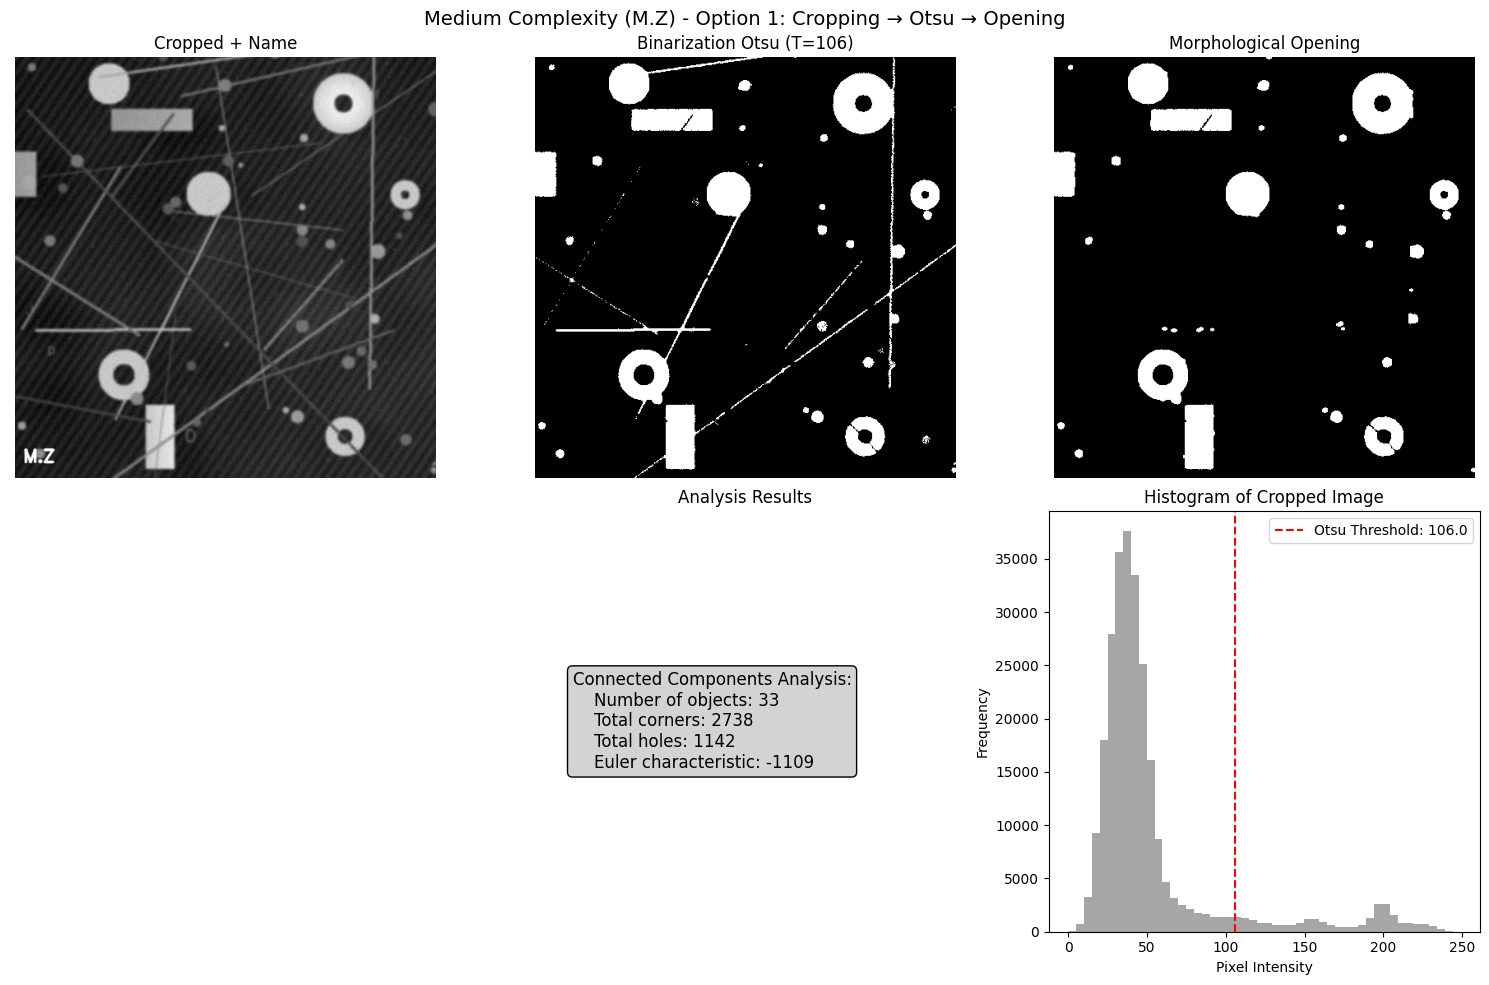


MEDIUM COMPLEXITY - DETAILED ANALYSIS RESULTS:
True number of objects: 10
Detected objects: 33
Total corners found: 2738
Total holes detected: 1142
Euler characteristic: -1109
Counting error: 23

OTSU PERFORMANCE ANALYSIS:
------------------------------
✗ Otsu thresholding: POOR PERFORMANCE (large error)

HOLES ANALYSIS:
------------------------------
Objects with holes detected: True
Average holes per object: 34.61


In [10]:
def crop_image(img, crop_percent=0.8):
    H, W = img.shape
    h_crop = int(H * crop_percent); w_crop = int(W * crop_percent)
    y_start = (H - h_crop) // 2; x_start = (W - w_crop) // 2
    return img[y_start:y_start+h_crop, x_start:x_start+w_crop]

def process_image_option1(img_raw, gt_mask, title):
    # 1. Cropping
    img_cropped = crop_image(img_raw, crop_percent=0.8)

    # 2. Binarisation OTSU
    ret_otsu, bin_otsu = cv.threshold(img_cropped, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 3. Morphology (5x5 Ellipse Opening)
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
    bin_otsu_opened = cv.morphologyEx(bin_otsu, cv.MORPH_OPEN, kernel)
    bin_otsu_opened_closed = cv.morphologyEx(bin_otsu_opened, cv.MORPH_CLOSE, kernel)

    # 4. تحليل المكونات المترابطة - ADDED ANALYSIS CALL
    analysis_results = analyze_connected_components(bin_otsu_opened_closed)

    # Added the name and the transformation for the display
    display_img = img_cropped.copy()
    cv.putText(display_img, 'M.Z', (10, display_img.shape[0] - 20), cv.FONT_HERSHEY_SIMPLEX, 0.7, 255, 2, cv.LINE_AA)

    # Display - UPDATED LAYOUT
    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    plt.suptitle(f'{title} - Option 1: Cropping → Otsu → Opening', fontsize=14)

    # الصف الأول: الصور
    ax[0, 0].imshow(display_img, cmap='gray'); ax[0, 0].set_title('Cropped + Name'); ax[0, 0].axis('off')
    ax[0, 1].imshow(bin_otsu, cmap='gray'); ax[0, 1].set_title(f'Binarization Otsu (T={ret_otsu:.0f})'); ax[0, 1].axis('off')
    ax[0, 2].imshow(bin_otsu_opened, cmap='gray'); ax[0, 2].set_title('Morphological Opening'); ax[0, 2].axis('off')

    # الصف الثاني: نتائج التحليل والرسم البياني - ADDED ANALYSIS DISPLAY
    ax[1, 0].axis('off')  #

    # عرض نتائج التحليل كنص
    analysis_text = f"""Connected Components Analysis:
    Number of objects: {analysis_results['num_objects']}
    Total corners: {analysis_results['total_corners']}
    Total holes: {analysis_results['total_holes']}
    Euler characteristic: {analysis_results['euler_characteristic']}"""

    ax[1, 1].text(0.1, 0.5, analysis_text, fontsize=12, verticalalignment='center',
                  transform=ax[1, 1].transAxes, bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray"))
    ax[1, 1].set_title('Analysis Results'); ax[1, 1].axis('off')

    # عرض الرسم البياني للصورة المقطوعة - ADDED HISTOGRAM
    ax[1, 2].hist(img_cropped.ravel(), bins=50, color='gray', alpha=0.7)
    ax[1, 2].axvline(x=ret_otsu, color='red', linestyle='--', label=f'Otsu Threshold: {ret_otsu:.1f}')
    ax[1, 2].set_title('Histogram of Cropped Image')
    ax[1, 2].set_xlabel('Pixel Intensity'); ax[1, 2].set_ylabel('Frequency')
    ax[1, 2].legend()

    plt.tight_layout(); plt.show()

    return analysis_results  # RETURN RESULTS FOR COMPARISON

# --- Execution ---
print("Generation of the image of Medium Complexity...")
img_medium, gt_medium, n_medium = generate_synthetic_random(
    n_circles=(6, 8), n_rects=(3, 5), with_holes=True, clutter=0.0
)
print(f"True number of objects: {n_medium}")

# استدعاء الدالة مع حفظ النتائج للمقارنة - ADDED ANALYSIS CALL
results_medium = process_image_option1(img_medium, gt_medium, "Medium Complexity (M.Z)")

# طباعة نتائج التحليل التفصيلية - ADDED DETAILED OUTPUT
print("\n" + "="*60)
print("MEDIUM COMPLEXITY - DETAILED ANALYSIS RESULTS:")
print("="*60)
print(f"True number of objects: {n_medium}")
print(f"Detected objects: {results_medium['num_objects']}")
print(f"Total corners found: {results_medium['total_corners']}")
print(f"Total holes detected: {results_medium['total_holes']}")
print(f"Euler characteristic: {results_medium['euler_characteristic']}")
print(f"Counting error: {abs(results_medium['num_objects'] - n_medium)}")

# تحليل أداء Otsu - ADDED OTSU PERFORMANCE ANALYSIS
print("\nOTSU PERFORMANCE ANALYSIS:")
print("-" * 30)
if results_medium['num_objects'] == n_medium:
    print("✓ Otsu thresholding: PERFECT MATCH")
elif abs(results_medium['num_objects'] - n_medium) <= 2:
    print("✓ Otsu thresholding: GOOD PERFORMANCE (small error)")
else:
    print("✗ Otsu thresholding: POOR PERFORMANCE (large error)")

# تحليل الثقوب - ADDED HOLES ANALYSIS
print(f"\nHOLES ANALYSIS:")
print("-" * 30)
print(f"Objects with holes detected: {results_medium['total_holes'] > 0}")
if results_medium['total_holes'] > 0:
    print(f"Average holes per object: {results_medium['total_holes'] / results_medium['num_objects']:.2f}")

High Complexity image Generation...
True number of objects: 25


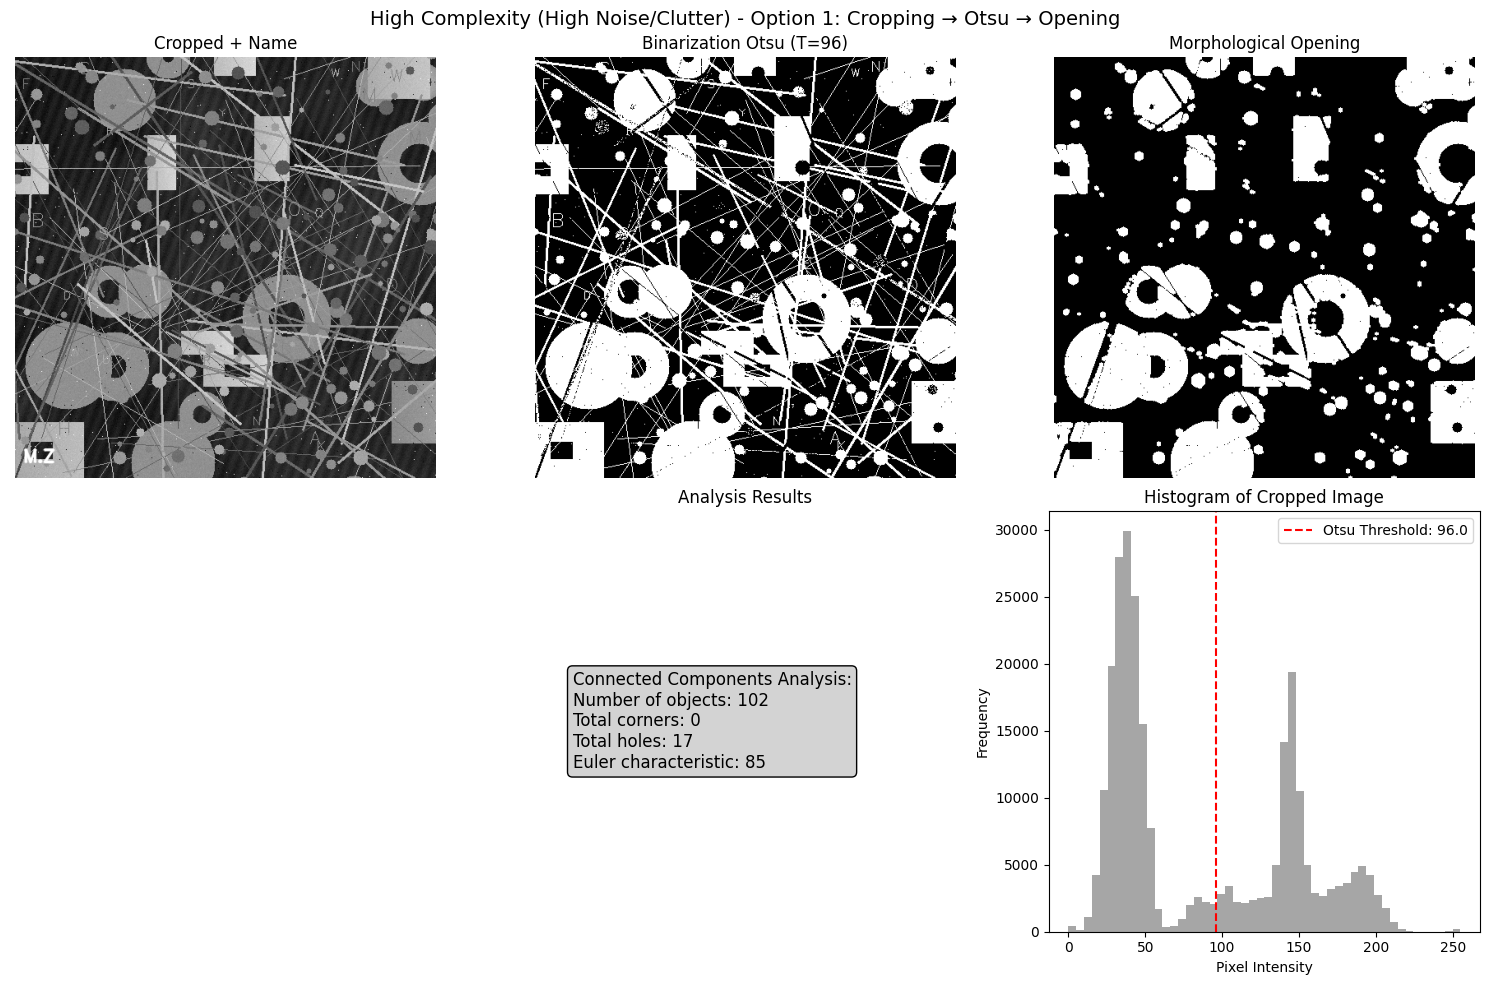


Detailed Analysis Results:
True number of objects: 25
Detected objects: 102
Total corners found: 0
Total holes detected: 17
Euler characteristic: 85
Counting error: 77


In [34]:


def crop_image(img, crop_percent=0.8):
    H, W = img.shape
    h_crop = int(H * crop_percent); w_crop = int(W * crop_percent)
    y_start = (H - h_crop) // 2; x_start = (W - w_crop) // 2
    return img[y_start:y_start+h_crop, x_start:x_start+w_crop]

def analyze_connected_components(bin_img):
    # تحليل المكونات المترابطة مع حساب الثقوب ومعامل أويلر
    num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(bin_img, connectivity=8)
    num_objects = num_labels - 1  # تجاهل الخلفية

    total_holes = 0
    total_corners = 0  # افتراض 0 مؤقتاً
    for label in range(1, num_labels):
        component_mask = (labels == label).astype('uint8') * 255
        contours, hierarchy = cv.findContours(component_mask, cv.RETR_CCOMP, cv.CHAIN_APPROX_SIMPLE)
        holes = 0
        if hierarchy is not None:
            for h in hierarchy[0]:
                if h[3] != -1:
                    holes += 1
        total_holes += holes

    euler_characteristic = num_objects - total_holes

    return {
        'num_objects': num_objects,
        'total_holes': total_holes,
        'total_corners': total_corners,
        'euler_characteristic': euler_characteristic
    }

def process_image_option1(img_raw, gt_mask, title):
    # 1. Cropping
    img_cropped = crop_image(img_raw, crop_percent=0.8)

    # 2. Binarization OTSU
    ret_otsu, bin_otsu = cv.threshold(img_cropped, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 3. Morphologie (Opening 5x5 Ellipse)
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
    bin_otsu_opened = cv.morphologyEx(bin_otsu, cv.MORPH_OPEN, kernel)
    bin_otsu_opened_closed = cv.morphologyEx(bin_otsu_opened, cv.MORPH_CLOSE, kernel)

    # 4. تحليل المكونات المترابطة
    analysis_results = analyze_connected_components(bin_otsu_opened_closed)

    # إضافة النص على الصورة
    display_img = img_cropped.copy()
    cv.putText(display_img, 'M.Z', (10, display_img.shape[0] - 20), cv.FONT_HERSHEY_SIMPLEX, 0.7, 255, 2, cv.LINE_AA)

    # العرض باستخدام 2 صف و3 أعمدة
    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    plt.suptitle(f'{title} - Option 1: Cropping → Otsu → Opening', fontsize=14)

    ax[0, 0].imshow(display_img, cmap='gray'); ax[0, 0].set_title('Cropped + Name'); ax[0, 0].axis('off')
    ax[0, 1].imshow(bin_otsu, cmap='gray'); ax[0, 1].set_title(f'Binarization Otsu (T={ret_otsu:.0f})'); ax[0, 1].axis('off')
    ax[0, 2].imshow(bin_otsu_opened, cmap='gray'); ax[0, 2].set_title('Morphological Opening'); ax[0, 2].axis('off')

    ax[1, 0].axis('off')
    analysis_text = f"""Connected Components Analysis:
Number of objects: {analysis_results['num_objects']}
Total corners: {analysis_results['total_corners']}
Total holes: {analysis_results['total_holes']}
Euler characteristic: {analysis_results['euler_characteristic']}"""
    ax[1, 1].text(0.1, 0.5, analysis_text, fontsize=12, verticalalignment='center',
                  transform=ax[1, 1].transAxes, bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray"))
    ax[1, 1].set_title('Analysis Results'); ax[1, 1].axis('off')

    ax[1, 2].hist(img_cropped.ravel(), bins=50, color='gray', alpha=0.7)
    ax[1, 2].axvline(x=ret_otsu, color='red', linestyle='--', label=f'Otsu Threshold: {ret_otsu:.1f}')
    ax[1, 2].set_title('Histogram of Cropped Image')
    ax[1, 2].set_xlabel('Pixel Intensity'); ax[1, 2].set_ylabel('Frequency')
    ax[1, 2].legend()

    plt.tight_layout()
    plt.show()

    return analysis_results


# --- Execution Example ---
print("High Complexity image Generation...")
img_high, gt_high, n_high = generate_synthetic_random(
    n_circles=(10, 16), n_rects=(8, 14), with_holes=True, clutter=0.75
)
print(f"True number of objects: {n_high}")
results_high = process_image_option1(img_high, gt_high, "High Complexity (High Noise/Clutter)")

print("\nDetailed Analysis Results:")
print(f"True number of objects: {n_high}")
print(f"Detected objects: {results_high['num_objects']}")
print(f"Total corners found: {results_high['total_corners']}")
print(f"Total holes detected: {results_high['total_holes']}")
print(f"Euler characteristic: {results_high['euler_characteristic']}")
print(f"Counting error: {abs(results_high['num_objects'] - n_high)}")


## ПРИЛОЖЕНИЕ 1. Описание функций
- `cv.imread`/`cv.imwrite` — чтение/запись; `cv.imshow`/`cv.waitKey` — показ
- `cv.resize` (интерполяции: NEAREST, LINEAR, CUBIC, AREA, LANCZOS4), `cv.flip` — геометрия.
- `cv.cvtColor` — цветовые пространства; серый канал: `COLOR_BGR2GRAY`.
- `cv.threshold` — глобальная бинаризация (режимы BINARY, BINARY_INV …), `cv.adaptiveThreshold` — адаптивная (Mean/Gaussian).
- `cv.blur`, `cv.GaussianBlur` — сглаживание; `cv.filter2D` — общая свёртка ядром (в т.ч. резкость/рельеф).
- `cv.createCLAHE` — локальная эквализация гистограммы (clipLimit, tileGridSize).
- `cv.Canny`, `cv.findContours` — контуры
- `dlib.get_frontal_face_detector`, `dlib.shape_predictor` — детекция лиц и 68-точек.


In [16]:
!apt-get install -y build-essential cmake
!apt-get install -y libopenblas-dev liblapack-dev
!apt-get install -y libx11-dev libgtk-3-dev
!pip install dlib


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
build-essential is already the newest version (12.9ubuntu3).
cmake is already the newest version (3.22.1-1ubuntu1.22.04.2).
0 upgraded, 0 newly installed, 0 to remove and 38 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
liblapack-dev is already the newest version (3.10.0-2ubuntu1).
libopenblas-dev is already the newest version (0.3.20+ds-1).
0 upgraded, 0 newly installed, 0 to remove and 38 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libgtk-3-dev is already the newest version (3.24.33-1ubuntu2.2).
libx11-dev is already the newest version (2:1.7.5-1ubuntu0.3).
0 upgraded, 0 newly installed, 0 to remove and 38 not upgraded.


# Пример фрагмента кода python для детектирования особых точек лица с использованием библиотеки dlib

In [19]:
# @title
# Выбор детекторов:

# детектор лица на изображении
detector = dlib.get_frontal_face_detector()
# детектор контура лица (68 точек)
predictor = dlib.shape_predictor('shape_predic'
'tor_68_face_landmarks.dat')
for file in face_images:
    image = cv2.imread(file)


NameError: name 'dlib' is not defined

In [20]:
# @title
# Поиск и отображение на изображение особых точек лица:

rects = detector(gray, 1)
for rect in rects:
# нахождение 68 точек для каждого найденного лица
    shape = predictor(gray, rect)
for i in range(0, 68):
    # отображение точек
    cv2.circle(image, (shape.part(i).x, shape.part(i).y),
    1, (0, 0, 255), -1)
cv2.imwrite(f'./output/{os.path.split(file)[-1]}', image)


NameError: name 'detector' is not defined

# Примеры реализации базовых процедур обработки изображений на языке программирования Python с использованием OpenCV

In [21]:
# @title
# Преобразование цветного изображения в градации серого
from google.colab.patches import cv2_imshow

import os, cv2 as cv
image = cv.imread("./myimg.jpg")
cv2_imshow(image)
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
cv2_imshow(gray_image)



AttributeError: 'NoneType' object has no attribute 'clip'

In [22]:
# @title
# Добавление тестовой надписи на изображение

import os, cv2 as cv
image = cv.imread("./myimg.jpg")
output = image.copy()
cv.putText(output, "Image with text", (50, 50),
    cv.FONT_HERSHEY_SIMPLEX, 2, (250, 80, 50), 3)
cv.imshow("Изображение с текстом", output)
cv.waitKey()


AttributeError: 'NoneType' object has no attribute 'copy'

In [ ]:
img, gt, n = generate_synthetic_random(
    n_circles=(4, 6),
    n_rects=(2, 4),
    with_holes=False, # Pas de trous
    clutter=0.0 # Pas de bruit/lignes/texte aléatoire
)

print(f'Image de Faible Complexité - Vrai nombre d\'objets: {n}')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Image de Faible Complexité'); ax[0].axis('off')
ax[1].imshow(gt, cmap='gray', vmin=0, vmax=255); ax[1].set_title('GT Mask'); ax[1].axis('off')
plt.tight_layout(); plt.show()


In [24]:
# تحميل النموذج المضغوط
!wget http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2

# فك الضغط
!bunzip2 shape_predictor_68_face_landmarks.dat.bz2

# ثم استدعاء النموذج
import dlib
predictor = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")


--2025-10-11 19:47:47--  http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Resolving dlib.net (dlib.net)... 107.180.26.78
Connecting to dlib.net (dlib.net)|107.180.26.78|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2 [following]
--2025-10-11 19:47:47--  https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Connecting to dlib.net (dlib.net)|107.180.26.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 64040097 (61M)
Saving to: ‘shape_predictor_68_face_landmarks.dat.bz2’

shape_predictor_68_ 100%[===================>]  61.07M  41.1MB/s    in 1.5s    

2025-10-11 19:47:49 (41.1 MB/s) - ‘shape_predictor_68_face_landmarks.dat.bz2’ saved [64040097/64040097]



Treatment of image1.JPG...


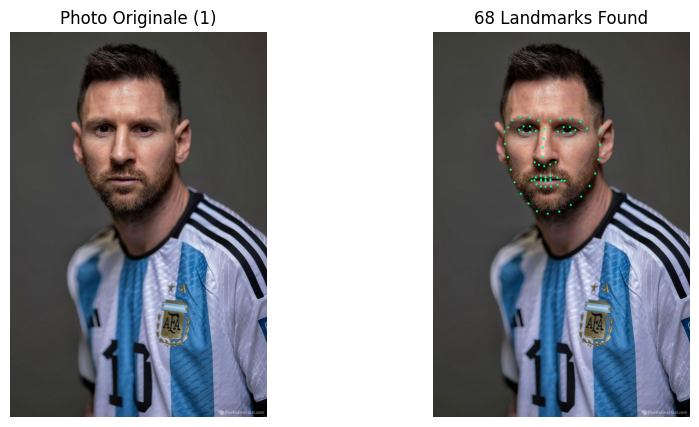

Treatment of image2.JPG...


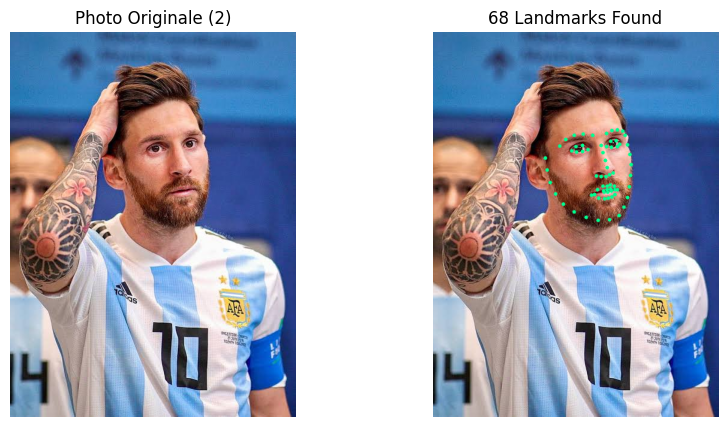

Treatment of image3.JPG...


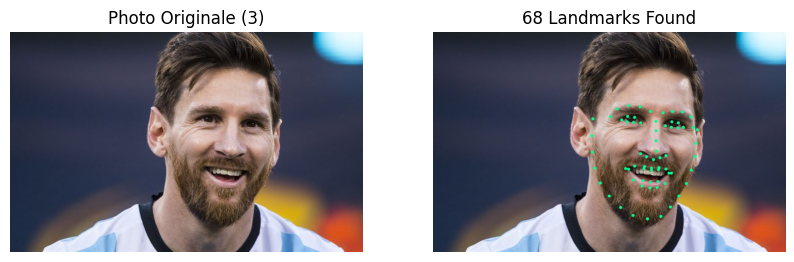

Treatment of image4.JPG...


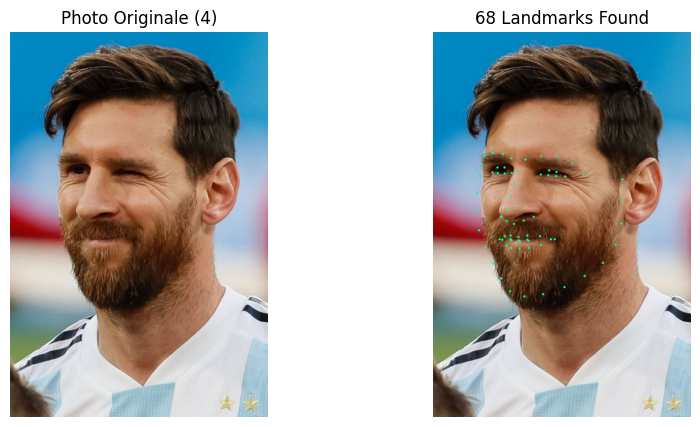

Treatment of image5.JPG...


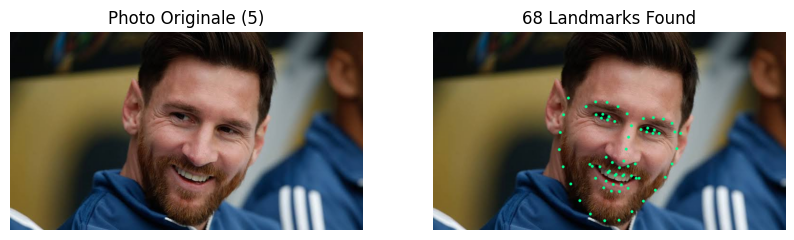

Finished !


In [33]:
# Importing the necessary libraries
import cv2
import dlib
import matplotlib.pyplot as plt

# Initialization of the dlib face detector (based on HOG)
detector = dlib.get_frontal_face_detector()
# Loading the predictor model of 68 facial landmarks
predictor = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")

# Loop over image files (from image1.jpg to image6.jpg)
for i in range(1, 6):
    # Setting the name of the image file
    filename = f"image{i}.JPG"
    print(f"Treatment of {filename}...")

    try:
        # Reading the image with OpenCV (BGR format by default)
        img = cv2.imread(filename)

        # Checking if the image has been loaded correctly
        if img is None:
            print(f"Error: Unable to load {filename}. The file may be missing or corrupted.")
            continue # Moving to the next iteration
        # BGR to RGB conversion for display with matplotlib
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        # BGR to grayscale conversion for face detection and landmark prediction
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Detection of faces in the grayscale image
        faces = detector(gray)

        # If at least one face has been found
        if len(faces) > 0:
            # Selection of the first detected face
            face = faces[0]
            # Prediction of the 68 facial landmarks
            landmarks = predictor(gray, face)

            # Creating a copy of the RGB image to draw the points
            result_img = img_rgb.copy()

            # Loop over the 68 landmarks
            for j in range(68):
                # Retrieving the x and y coordinates of the landmark
                x = landmarks.part(j).x
                y = landmarks.part(j).y

                # Drawing a green circle at the landmark
                # (0, 255, 0) corresponds to the Green color in BGR format, expected by cv2.circle
                cv2.circle(result_img, (x, y), 3, (0, 255, 144), -1)

            # --- Side-by-side image display ---
            plt.figure(figsize=(10, 5))

            # Original image (subgraph 1)
            plt.subplot(1, 2, 1)
            plt.imshow(img_rgb)
            plt.title(f"Photo Originale ({i})")
            plt.axis('off')

            # Image with the reference points (subgraph 2)
            plt.subplot(1, 2, 2)
            plt.imshow(result_img)
            plt.title(f"68 Landmarks Found")
            plt.axis('off')

            # Figure display
            plt.show()

        else:
            # Message if no face has been detected
            print(f"Photo image{i}.jpeg - Face not found")

    except Exception as e:
        # Capture and display of errors that occurred during processing
        print(f"Error with the photo image{i}.jpeg: {e}")

# Final message after the loop
print("Finished !")
